# Call the Team 4 layout server

Sends the example sketch (`static/sketch_example.jpg`) with an area, a bedroom count and balcony yes/no to `/api/design` and prints the 5 floor plans the server answers with.

The free Render service **sleeps after 15 minutes** without requests: the first call can take about a minute, and one design request takes a few minutes on the small free server.

Install once: `pip install requests pillow`

In [1]:
import base64, io, os, time
import requests
from PIL import Image
from IPython.display import display

# The live server on Render. Set LAYOUT_URL=http://localhost:7860 to test a local `python app.py`.
URL = os.environ.get("LAYOUT_URL", "https://team4-layout-server.onrender.com")
print("Calling", URL)

Calling https://team4-layout-server.onrender.com


## 1. Is the server ready?

In [2]:
health = requests.get(f"{URL}/health", timeout=180).json()
print("ok:", health["ok"])
print("model:", health["model"])
print("bedrooms:", health["bedrooms"], " area_m2:", health["area_m2"])

ok: True
model: LayoutCVAE decoder (Team 4, trained on ResPlan), ONNX
bedrooms: [1, 5]  area_m2: [25.0, 400.0]


## 2. One design request: photo of the sketch + area, bedrooms, balcony

`dxf=0` leaves out the DXF files to keep the answer small; the PNG previews are kept.

In [3]:
start = time.time()
with open("static/sketch_example.jpg", "rb") as f:
    answer = requests.post(f"{URL}/api/design", files={"photo": f},
                           data={"area_m2": 95, "bedrooms": 3, "balcony": 1, "dxf": 0},
                           timeout=900).json()
print(f"ok: {answer['ok']} | options: {len(answer.get('options', []))} | "
      f"server time: {answer.get('seconds')} s | round trip: {time.time() - start:.0f} s")
if not answer["ok"]:
    print("error:", answer.get("error"))
print("pictures:", answer.get("pictures"))

ok: True | options: 4 | server time: 38.59 s | round trip: 39 s
pictures: {'drawn': 60, 'usable': 4, 'dropped': {'cannot fit 3 bedrooms': 26, 'a bedroom is too small': 18, 'balcony asked': 5, 'no kitchen': 5, 'main bathroom too small': 2}}


## 3. The 5 options: score and rooms

In [4]:
for o in answer.get("options", []):
    s = o["summary"]
    print(f'#{o["rank"]}  score {o["score"]:.2f} | {s["bedrooms"]} bed, {s["bathrooms"]} bath, '
          f'{s["kitchens"]} kitchen, {s["balconies"]} balcony | rooms {s["rooms_m2"]:.1f} m2')
    for r in o["rooms"]:
        print(f'      {r["type"]:9} {r["area_m2"]:6.1f} m2')

#1  score 0.87 | 3 bed, 2 bath, 1 kitchen, 1 balcony | rooms 75.9 m2
      living      17.6 m2
      bedroom      9.0 m2
      bedroom     15.4 m2
      bathroom     5.4 m2
      bathroom     5.3 m2
      kitchen      7.7 m2
      balcony      8.2 m2
      bedroom     15.5 m2
#2  score 0.85 | 3 bed, 2 bath, 1 kitchen, 1 balcony | rooms 77.6 m2
      living      22.7 m2
      bedroom     10.5 m2
      bathroom     4.0 m2
      bathroom     2.2 m2
      kitchen      5.5 m2
      balcony      6.3 m2
      bedroom     21.7 m2
      bedroom     11.0 m2
#3  score 0.84 | 3 bed, 3 bath, 1 kitchen, 2 balcony | rooms 75.8 m2
      living      22.4 m2
      bedroom      9.5 m2
      bedroom     15.2 m2
      bathroom     2.7 m2
      bathroom     1.7 m2
      bathroom     5.2 m2
      kitchen      3.3 m2
      balcony      7.3 m2
      balcony      2.3 m2
      bedroom     15.8 m2
#4  score 0.84 | 3 bed, 2 bath, 1 kitchen, 1 balcony | rooms 70.8 m2
      living      20.2 m2
      bedroom     20.2

## 4. The previews

Option 1 (score 0.87)


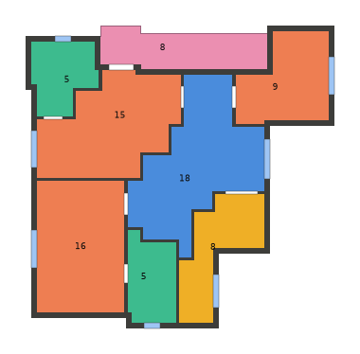

Option 2 (score 0.85)


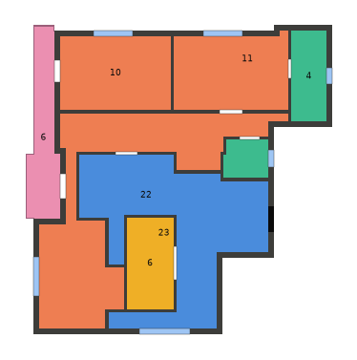

Option 3 (score 0.84)


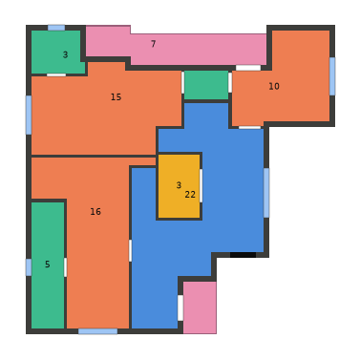

Option 4 (score 0.84)


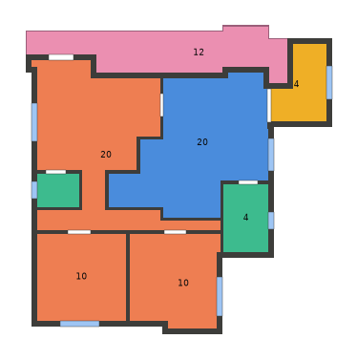

In [5]:
for o in answer.get("options", []):
    png = base64.b64decode(o["preview_png"].split(",", 1)[1])
    img = Image.open(io.BytesIO(png))
    img.thumbnail((360, 360))
    print(f'Option {o["rank"]} (score {o["score"]:.2f})')
    display(img)